# Sarcasm Detection

In [2]:
# PHASE 1: Install extra packages
# (Colab already has tensorflow, spacy, nltk, sklearn, pandas, matplotlib)
!pip install -q vaderSentiment contractions kagglehub
!python -m spacy download en_core_web_sm -q


✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [3]:
# Imports + NLTK resources
import os, re, glob
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import spacy
import tensorflow as tf
from sklearn.feature_extraction.text import CountVectorizer

for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)
from nltk.corpus import stopwords

nlp = spacy.load("en_core_web_sm")
sns.set_style("whitegrid")
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Notebook may live in notebooks/; artifacts live next to that folder.
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
for _d in ["data", "embeddings", "features", "models", "results/figures", "app"]:
    os.makedirs(_d, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("spaCy:", spacy.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "None - enable it in Runtime settings")


TensorFlow: 2.21.0
spaCy: 3.8.16
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
# Download GloVe 100d embeddings (~820 MB zip, takes 2-5 min; used in Phase 5)
if not os.path.exists("embeddings/glove.6B.100d.txt"):
    !wget -q --show-progress https://nlp.stanford.edu/data/glove.6B.zip
    !unzip -q -o glove.6B.zip glove.6B.100d.txt
    !mv glove.6B.100d.txt embeddings/glove.6B.100d.txt
    !rm glove.6B.zip
print("GloVe ready:", os.path.exists("embeddings/glove.6B.100d.txt"))


glove.6B.zip        100%[===================>] 822.24M  4.95MB/s    in 2m 47s  
GloVe ready: True


In [5]:
# PHASE 2: Load the News Headlines Sarcasm dataset
def load_data():
    try:
        import kagglehub
        path = kagglehub.dataset_download("rmisra/news-headlines-dataset-for-sarcasm-detection")
        files = glob.glob(os.path.join(path, "**", "*v2*.json"), recursive=True) \
             or glob.glob(os.path.join(path, "**", "*.json"), recursive=True)
        print("Loaded from Kaggle:", os.path.basename(files[0]))
        return pd.read_json(files[0], lines=True)
    except Exception as e:
        print("Kaggle download failed ->", e, "\nUsing fallback copy (v1 of dataset)")
        return pd.read_json("https://storage.googleapis.com/tensorflow-1-public/course3/sarcasm.json")

df = load_data()
print(df.shape)
df.head()


100%|██████████| 3.30M/3.30M [00:00<00:00, 5.10MB/s]

Extracting files...


Loaded from Kaggle: Sarcasm_Headlines_Dataset_v2.json
(28619, 3)


,is_sarcastic,headline,article_link
0,1,thirtysomething scientists unveil doomsday clo...,https://www.theonion.com/thirtysomething-scien...
1,0,dem rep. totally nails why congress is falling...,https://www.huffingtonpost.com/entry/donna-edw...
2,0,eat your veggies: 9 deliciously different recipes,https://www.huffingtonpost.com/entry/eat-your-...
3,1,inclement weather prevents liar from getting t...,https://local.theonion.com/inclement-weather-p...
4,1,mother comes pretty close to using word 'strea...,https://www.theonion.com/mother-comes-pretty-c...


In [6]:
# Basic inspection + cleanup
df = df[["headline", "is_sarcastic"]]
print(df.info())
print("\nMissing values:\n", df.isnull().sum())

dupes = df.duplicated(subset="headline").sum()
print(f"\nDuplicate headlines: {dupes}")
df = df.drop_duplicates(subset="headline").reset_index(drop=True)
print("Shape after dropping duplicates:", df.shape)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28619 entries, 0 to 28618
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   headline      28619 non-null  object
 1   is_sarcastic  28619 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 447.3+ KB
None

Missing values:
 headline        0
is_sarcastic    0
dtype: int64

Duplicate headlines: 116
Shape after dropping duplicates: (28503, 2)


is_sarcastic
0    14951
1    13552
Name: count, dtype: int64
is_sarcastic
0    52.5 %
1    47.5 %
Name: count, dtype: object


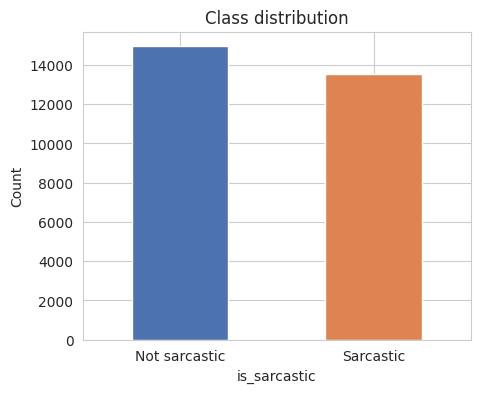

In [7]:
# Class balance
counts = df["is_sarcastic"].value_counts()
print(counts)
print((counts / len(df) * 100).round(1).astype(str) + " %")

ax = counts.rename({0: "Not sarcastic", 1: "Sarcastic"}).plot(
    kind="bar", color=["#4C72B0", "#DD8452"], rot=0, figsize=(5, 4))
ax.set_title("Class distribution"); ax.set_ylabel("Count")
plt.show()


is_sarcastic            0        1
word_count count  14951.0  13552.0
           mean       9.8     10.3
           std        2.9      3.9
           min        2.0      2.0
           25%        8.0      8.0
           50%       10.0     10.0
           75%       12.0     13.0
           max       38.0    151.0
char_count count  14951.0  13552.0
           mean      59.6     65.4
           std       17.3     23.5
           min        7.0      8.0
           25%       48.0     49.0
           50%       61.0     64.0
           75%       71.0     80.0
           max      228.0    926.0


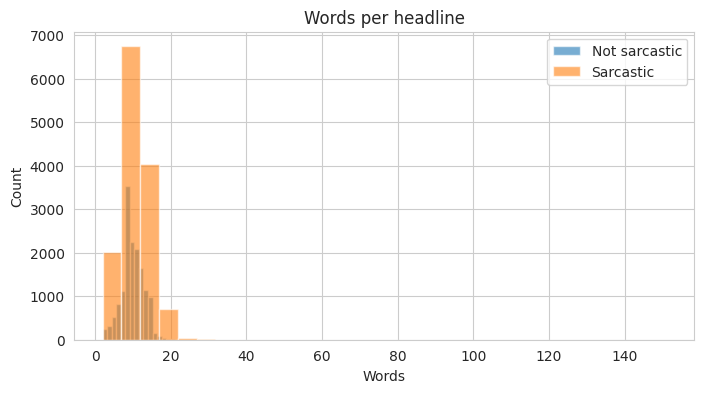

95th percentile length -> MAX_LEN = 16 tokens


In [8]:
# Headline length analysis -> decides MAX_LEN for padding in Phase 5
df["word_count"] = df["headline"].str.split().str.len()
df["char_count"] = df["headline"].str.len()
print(df.groupby("is_sarcastic")[["word_count", "char_count"]].describe().T.round(1))

plt.figure(figsize=(8, 4))
for label, name in [(0, "Not sarcastic"), (1, "Sarcastic")]:
    plt.hist(df[df.is_sarcastic == label]["word_count"], bins=30, alpha=0.6, label=name)
plt.title("Words per headline"); plt.xlabel("Words"); plt.ylabel("Count"); plt.legend()
plt.show()

MAX_LEN = int(np.percentile(df["word_count"], 95))
print(f"95th percentile length -> MAX_LEN = {MAX_LEN} tokens")


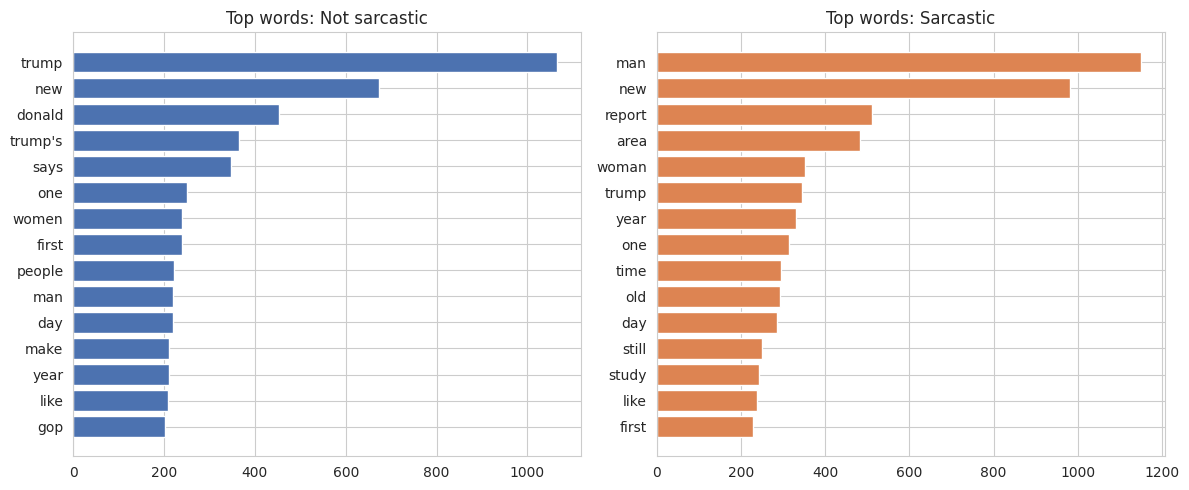

In [9]:
# Most common words per class (stop words removed ONLY for this EDA view)
stop_words = set(stopwords.words("english"))

def top_words(texts, n=15):
    words = [w for t in texts for w in re.findall(r"[a-z']+", t.lower())
             if w not in stop_words and len(w) > 2]
    return Counter(words).most_common(n)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (label, name) in zip(axes, [(0, "Not sarcastic"), (1, "Sarcastic")]):
    words, freqs = zip(*top_words(df[df.is_sarcastic == label]["headline"]))
    ax.barh(words[::-1], freqs[::-1], color="#4C72B0" if label == 0 else "#DD8452")
    ax.set_title(f"Top words: {name}")
plt.tight_layout(); plt.show()


In [10]:
# Most common bigrams per class (stop words KEPT - phrases matter for sarcasm)
def top_ngrams(texts, n=15, ngram=(2, 2)):
    vec = CountVectorizer(ngram_range=ngram).fit(texts)
    sums = vec.transform(texts).sum(axis=0).A1
    vocab = vec.get_feature_names_out()
    return sorted(zip(vocab, sums), key=lambda x: -x[1])[:n]

for label, name in [(0, "Not sarcastic"), (1, "Sarcastic")]:
    print(f"\n--- Top bigrams: {name} ---")
    for phrase, c in top_ngrams(df[df.is_sarcastic == label]["headline"]):
        print(f"{phrase:<25} {c}")



--- Top bigrams: Not sarcastic ---
donald trump              447
in the                    308
of the                    280
how to                    203
to the                    164
to be                     163
on the                    158
and the                   146
hillary clinton           140
for the                   132
the world                 123
at the                    116
is the                    110
need to                   104
from the                  98

--- Top bigrams: Sarcastic ---
area man                  260
out of                    208
to be                     192
year old                  188
to get                    131
white house               127
study finds               123
going to                  115
of the                    88
forced to                 80
trying to                 80
to make                   78
introduces new            68
of americans              67
man who                   66


In [11]:
# Style cues per class -> tells you which handcrafted features are worth it in Phase 4
style = pd.DataFrame({
    "is_sarcastic": df["is_sarcastic"],
    "has_exclaim":  df["headline"].str.contains("!", regex=False),
    "has_question": df["headline"].str.contains("?", regex=False),
    "has_quotes":   df["headline"].str.contains(r"['\"‘’“”]"),
    "has_digit":    df["headline"].str.contains(r"\d"),
    "has_uppercase": df["headline"].str.contains(r"[A-Z]"),
})
print((style.groupby("is_sarcastic").mean() * 100).round(2).T.rename(
    columns={0: "Not sarcastic %", 1: "Sarcastic %"}))
# NOTE: this dataset is already lowercased, so has_uppercase will be ~0%.
# That means the caps-ratio feature from the plan is useless here - skip it in Phase 4.


is_sarcastic   Not sarcastic %  Sarcastic %
has_exclaim               1.08         0.27
has_question              4.86         0.73
has_quotes               37.94        26.48
has_digit                14.98        14.35
has_uppercase             0.00         0.00


In [12]:
# Read some real examples - always eyeball your data
pd.set_option("display.max_colwidth", 120)
for label, name in [(0, "NOT SARCASTIC"), (1, "SARCASTIC")]:
    print(f"\n===== {name} =====")
    for h in df[df.is_sarcastic == label]["headline"].sample(5, random_state=SEED):
        print("-", h)



===== NOT SARCASTIC =====
- 'california country' singer turns ballad into heartbreaking plea for queer inclusion
- report: trump bans 'transgender,' 'fetus,' 'science-based' from cdc documents
- test-driven teacher evaluations strike out
- john mccain, czar hater, calls for ebola czar
- channing tatum and jenna dewan tatum slay on the golden globes red carpet

===== SARCASTIC =====
- panicking mitch mcconnell shoves entire senate healthcare bill into mouth as democrat walks past
- tear gas manufacturers worried about association with everything tear gas used for
- report: middle east quickly running out of land area for violence to spill over to
- bush seeking non-masturbating surgeon general
- thursday cry moved up to wednesday due to scheduling conflict


In [13]:
# Save for Phase 3
df[["headline", "is_sarcastic"]].to_csv("data/sarcasm_base.csv", index=False)
print(f"Saved {len(df)} rows to data/sarcasm_base.csv | MAX_LEN = {MAX_LEN}")

# Optional: Colab deletes files when the session ends. To keep them, uncomment:
from google.colab import drive
drive.mount("/content/drive")
!mkdir -p /content/drive/MyDrive/sarcasm_project
!cp data/sarcasm_base.csv embeddings/glove.6B.100d.txt /content/drive/MyDrive/sarcasm_project/


Saved 28503 rows to sarcasm_base.csv | MAX_LEN = 16
Mounted at /content/drive


In [14]:
# =====================================================================
# SARCASM DETECTION - PHASE 3: Text Preprocessing
# Add these cells BELOW cell 12 in the same Colab notebook.
# Produces two text columns:
#   clean_text     -> light cleaning, all words kept   (for BiLSTM + GloVe)
#   processed_text -> lemmatized, custom stop words out (for TF-IDF)
#   pos_tags       -> POS tag sequence                  (reused in Phase 4)
# =====================================================================


# ============================ CELL 13 ===============================
# Restore data if the Colab session restarted
# (after a restart, first re-run cells 1-2 for installs and imports)
try:
    df
except NameError:
    df = pd.read_csv("data/sarcasm_base.csv")  # or the Drive path if you saved it there
df = df[["headline", "is_sarcastic"]].copy()
print(df.shape)


(28503, 2)


In [15]:

# ============================ CELL 14 ===============================
# Step 1 - Cleaning / normalization
import contractions

URL_RE = re.compile(r"https?://\S+|www\.\S+")

def clean_text(text):
    text = str(text).lower()
    text = URL_RE.sub(" ", text)                       # URLs
    text = re.sub(r"<.*?>", " ", text)                 # HTML tags
    text = text.replace("’", "'").replace("‘", "'")    # curly apostrophes
    text = contractions.fix(text)                      # can't -> cannot, don't -> do not
    text = re.sub(r"\.{2,}|…", " ... ", text)          # keep ellipsis as one token
    text = re.sub(r"([!?])", r" \1 ", text)            # keep ! and ? as separate tokens
    text = re.sub(r"[^a-z0-9\s!?.']", " ", text)       # drop other symbols
    text = re.sub(r"(?<!\.)\.(?!\.)", " ", text)       # drop single full stops
    text = re.sub(r"(?<![a-z])'|'(?![a-z])", " ", text)  # drop stray quote marks
    return re.sub(r"\s+", " ", text).strip()

for s in ["you won't BELIEVE what this guy did...", "oh great, another 'genius' idea!",
          "check https://t.co/x <b>now</b>?!"]:
    print(f"{s!r:50} -> {clean_text(s)!r}")

df["clean_text"] = df["headline"].apply(clean_text)

"you won't BELIEVE what this guy did..."           -> 'you will not believe what this guy did ...'
"oh great, another 'genius' idea!"                 -> 'oh great another genius idea !'
'check https://t.co/x <b>now</b>?!'                -> 'check now ? !'


In [16]:

# ============================ CELL 15 ===============================
# Step 2 - Custom stop word list (sarcasm-aware)
# Standard lists delete negations and intensifiers, which are sarcasm cues.
KEEP_WORDS = {"not", "no", "nor", "never", "so", "very", "just", "too", "only",
              "more", "most", "again", "all", "against", "same", "few", "over",
              "off", "what", "why", "how", "really", "such", "own"}
KEEP_PUNCT = {"!", "?", "..."}
CUSTOM_STOPS = set(stopwords.words("english")) - KEEP_WORDS

print(f"NLTK stop words: {len(stopwords.words('english'))} | custom list: {len(CUSTOM_STOPS)}")
print("Kept on purpose:", sorted(KEEP_WORDS & set(stopwords.words("english"))))


NLTK stop words: 198 | custom list: 176
Kept on purpose: ['again', 'against', 'all', 'few', 'how', 'just', 'more', 'most', 'no', 'nor', 'not', 'off', 'only', 'over', 'own', 'same', 'so', 'such', 'too', 'very', 'what', 'why']


In [17]:
# ============================ CELL 16 ===============================
# Step 3 - Tokenization: compare tokenizers (good material for the report)
from nltk.tokenize import word_tokenize, TweetTokenizer

sample = "area man's 'totally thrilled' about monday... again!"
print("str.split()     :", sample.split())
print("NLTK word_tok.  :", word_tokenize(sample))
print("NLTK TweetTok.  :", TweetTokenizer().tokenize(sample))
print("spaCy           :", [t.text for t in nlp(sample)])


str.split()     : ['area', "man's", "'totally", "thrilled'", 'about', 'monday...', 'again!']
NLTK word_tok.  : ['area', 'man', "'s", "'totally", 'thrilled', "'", 'about', 'monday', '...', 'again', '!']
NLTK TweetTok.  : ['area', "man's", "'", 'totally', 'thrilled', "'", 'about', 'monday', '...', 'again', '!']
spaCy           : ['area', 'man', "'s", "'", 'totally', 'thrilled', "'", 'about', 'monday', '...', 'again', '!']


In [18]:
# ============================ CELL 17 ===============================
# Steps 4-6 - spaCy tokenization + POS tagging + lemmatization + stop word removal
# One pass over the data; POS tags are saved so Phase 4 does not re-run spaCy.
# Takes ~1-3 minutes on Colab.
from tqdm.auto import tqdm

def spacy_process(texts, batch_size=1000):
    processed, pos_seqs = [], []
    for doc in tqdm(nlp.pipe(texts, batch_size=batch_size, disable=["ner", "parser"]),
                    total=len(texts)):
        # POS tags on the FULL sentence (stop words included) - better for counting later
        pos_seqs.append(" ".join(t.pos_ for t in doc if not t.is_space))

        tokens = []
        for t in doc:
            if t.is_space:
                continue
            if t.is_punct:
                if t.text in KEEP_PUNCT:
                    tokens.append(t.text)
                continue
            lemma = t.lemma_.lower()
            if lemma in CUSTOM_STOPS or t.text in CUSTOM_STOPS or lemma.startswith("'"):
                continue
            tokens.append(lemma)
        processed.append(" ".join(tokens))
    return processed, pos_seqs

df["processed_text"], df["pos_tags"] = spacy_process(df["clean_text"].tolist())

  0%|          | 0/28503 [00:00<?, ?it/s]

In [19]:
# ============================ CELL 18 ===============================
# Before vs after - pick a few examples for your report
pd.set_option("display.max_colwidth", 80)
df[["headline", "clean_text", "processed_text", "pos_tags"]].sample(6, random_state=SEED)

,headline,clean_text,processed_text,pos_tags
24106,marco rubio nabs his first 2016 win in minnesota gop presidential caucus,marco rubio nabs his first 2016 win in minnesota gop presidential caucus,marco rubio nab first 2016 win minnesota gop presidential caucus,ADJ PROPN VERB PRON ADJ NUM NOUN ADP PROPN PROPN ADJ NOUN
6020,oops: hot mic broadcasts al roker going to the bathroom,oops hot mic broadcasts al roker going to the bathroom,oops hot mic broadcast al roker go bathroom,INTJ ADJ ADJ NOUN PROPN NOUN VERB ADP DET NOUN
20292,white house pretty sure uzbekistan diplomat stole a bunch of soap,white house pretty sure uzbekistan diplomat stole a bunch of soap,white house pretty sure uzbekistan diplomat steal bunch soap,PROPN PROPN ADV ADV ADJ NOUN VERB DET NOUN ADP NOUN
1433,sean hannity informs building tenants about deep-state conspiracy forcing hi...,sean hannity informs building tenants about deep state conspiracy forcing hi...,sean hannity inform build tenant deep state conspiracy force triple rent,PROPN NOUN NOUN VERB NOUN ADP ADJ NOUN NOUN VERB PRON PART ADJ NOUN
27087,switching to renewables will save millions of american lives,switching to renewables will save millions of american lives,switch renewable save million american life,VERB ADP NOUN AUX VERB NOUN ADP ADJ NOUN
8393,ellie goulding and james corden perform 'love me like you do' remix,ellie goulding and james corden perform love me like you do remix,ellie goulding james corden perform love like remix,PROPN NOUN CCONJ PROPN PROPN VERB VERB PRON ADP PRON AUX NOUN


In [20]:
# ============================ CELL 19 ===============================
# Sanity checks + vocabulary stats
def vocab(series):
    return set(w for t in series for w in t.split())

for col in ["headline", "clean_text", "processed_text"]:
    lens = df[col].str.split().str.len()
    print(f"{col:<15} vocab = {len(vocab(df[col])):>6} | avg tokens = {lens.mean():.1f}")

empty = (df["processed_text"].str.strip() == "").sum()
print(f"\nRows that became empty after stop word removal: {empty}")
# For TF-IDF an empty row is fine (all-zero vector); clean_text is never empty.

print("\nMost common POS tags overall:")
print(Counter(" ".join(df["pos_tags"]).split()).most_common(10))

headline        vocab =  38234 | avg tokens = 10.1
clean_text      vocab =  27528 | avg tokens = 10.4
processed_text  vocab =  20741 | avg tokens = 7.7

Rows that became empty after stop word removal: 1

Most common POS tags overall:
[('NOUN', 91916), ('VERB', 43648), ('ADP', 34950), ('PROPN', 30607), ('ADJ', 27476), ('PART', 12780), ('DET', 12456), ('PRON', 11992), ('AUX', 11020), ('ADV', 10671)]


In [21]:
# ============================ CELL 20 ===============================
# Save for Phase 4
df.to_csv("data/sarcasm_preprocessed.csv", index=False)
print("Saved data/sarcasm_preprocessed.csv with columns:", list(df.columns))

# If you mounted Drive in cell 12, also copy it there:
!cp data/sarcasm_preprocessed.csv /content/drive/MyDrive/sarcasm_project/


Saved sarcasm_preprocessed.csv with columns: ['headline', 'is_sarcastic', 'clean_text', 'processed_text', 'pos_tags']


In [22]:
# =====================================================================
# SARCASM DETECTION - PHASE 4: NLP Feature Extraction
# Add these cells BELOW cell 20 in the same Colab notebook.
#
# IMPORTANT: the train/test split happens HERE (moved up from Phase 5).
# TF-IDF, SVD and the scaler must learn from training data only;
# fitting them on all data leaks test information and inflates scores.
# =====================================================================


# ============================ CELL 21 ===============================
# Restore data if the session restarted (re-run cells 1-2 first)
try:
    df["pos_tags"]
except (NameError, KeyError):
    df = pd.read_csv("data/sarcasm_preprocessed.csv")
df["processed_text"] = df["processed_text"].fillna("")  # empty rows load as NaN
print(df.shape)


(28503, 5)


In [23]:
# ============================ CELL 22 ===============================
# Train/test split - done ONCE, reused by every later phase
from sklearn.model_selection import train_test_split

train_idx, test_idx = train_test_split(
    df.index.values, test_size=0.2, stratify=df["is_sarcastic"], random_state=SEED)
y_train = df.loc[train_idx, "is_sarcastic"].values
y_test  = df.loc[test_idx,  "is_sarcastic"].values

np.save("features/train_idx.npy", train_idx); np.save("features/test_idx.npy", test_idx)
print(f"Train: {len(train_idx)} | Test: {len(test_idx)}")
print(f"Sarcastic share - train: {y_train.mean():.3f}, test: {y_test.mean():.3f}")


Train: 22802 | Test: 5701
Sarcastic share - train: 0.475, test: 0.476


In [24]:
# ============================ CELL 23 ===============================
# Feature group 1 - Sentiment + sentiment incongruity (VADER, on the RAW headline)
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
vader = SentimentIntensityAnalyzer()

def sentiment_features(text):
    s = vader.polarity_scores(text)
    words = re.findall(r"[a-z']+", text.lower())
    word_scores = [vader.lexicon[w] for w in words if w in vader.lexicon]
    n_pos = sum(1 for v in word_scores if v > 0)
    n_neg = sum(1 for v in word_scores if v < 0)
    return {
        "vader_pos": s["pos"], "vader_neg": s["neg"],
        "vader_neu": s["neu"], "vader_compound": s["compound"],
        "n_pos_words": n_pos, "n_neg_words": n_neg,
        # incongruity: positive AND negative words in the same headline
        "sent_contrast": int(n_pos > 0 and n_neg > 0),
        "sent_gap": max(word_scores, default=0) - min(word_scores, default=0),
    }

print(sentiment_features("i just love being stuck in traffic"))
sent_df = pd.DataFrame([sentiment_features(t) for t in tqdm(df["headline"])])


{'vader_pos': 0.375, 'vader_neg': 0.179, 'vader_neu': 0.446, 'vader_compound': 0.4939, 'n_pos_words': 1, 'n_neg_words': 1, 'sent_contrast': 1, 'sent_gap': 4.2}


  0%|          | 0/28503 [00:00<?, ?it/s]

In [25]:
# ============================ CELL 24 ===============================
# Feature group 2 - POS features (from the tags saved in Phase 3)
INTENSIFIERS = {"so", "very", "really", "totally", "absolutely", "completely", "extremely",
                "literally", "truly", "incredibly", "utterly", "just", "definitely", "super"}
POS_OF_INTEREST = ["ADJ", "ADV", "INTJ", "VERB", "NOUN", "PROPN", "PRON", "NUM"]

def pos_features(pos_string, clean_text):
    tags = pos_string.split()
    n = max(len(tags), 1)
    feats = {f"pos_{p.lower()}_ratio": tags.count(p) / n for p in POS_OF_INTEREST}
    feats["n_intensifiers"] = sum(w in INTENSIFIERS for w in clean_text.split())
    return feats

pos_df = pd.DataFrame([pos_features(p, c) for p, c in zip(df["pos_tags"], df["clean_text"])])
pos_df.head(3)


,pos_adj_ratio,pos_adv_ratio,pos_intj_ratio,pos_verb_ratio,pos_noun_ratio,pos_propn_ratio,pos_pron_ratio,pos_num_ratio,n_intensifiers
0,0.000000,0.000000,0.0,0.250000,0.625000,0.000000,0.000000,0.000000,0
1,0.076923,0.153846,0.0,0.153846,0.153846,0.230769,0.000000,0.000000,1
2,0.142857,0.142857,0.0,0.142857,0.285714,0.000000,0.142857,0.142857,0


In [26]:
# ============================ CELL 25 ===============================
# Feature group 3 - Style / punctuation (caps ratio skipped: dataset is lowercase)
def style_features(text):
    words = text.split()
    return {
        "n_exclaim":  text.count("!"),
        "n_question": text.count("?"),
        "n_ellipsis": len(re.findall(r"\.{2,}|…", text)),
        "n_quotes":   len(re.findall(r"['\"‘’“”](?![a-z])|(?<![a-z])['\"‘’“”]", text)),
        "has_digit":  int(bool(re.search(r"\d", text))),
        "word_count": len(words),
        "avg_word_len": np.mean([len(w) for w in words]) if words else 0,
    }

style_df = pd.DataFrame([style_features(t) for t in df["headline"]])

handcrafted = pd.concat([sent_df, pos_df, style_df], axis=1)
print("Handcrafted features:", handcrafted.shape[1])
handcrafted.head(3)


Handcrafted features: 24


,vader_pos,vader_neg,vader_neu,vader_compound,n_pos_words,n_neg_words,sent_contrast,sent_gap,pos_adj_ratio,pos_adv_ratio,...,pos_pron_ratio,pos_num_ratio,n_intensifiers,n_exclaim,n_question,n_ellipsis,n_quotes,has_digit,word_count,avg_word_len
0,0.000,0.504,0.496,-0.7269,0,2,0,1.5,0.000000,0.000000,...,0.000000,0.000000,0,0,0,0,0,0,8,6.750000
1,0.000,0.118,0.882,-0.1531,0,1,0,0.0,0.076923,0.153846,...,0.000000,0.000000,1,0,0,0,0,0,13,5.153846
2,0.326,0.000,0.674,0.4404,1,0,0,0.0,0.142857,0.142857,...,0.142857,0.142857,0,0,0,0,0,1,7,6.142857


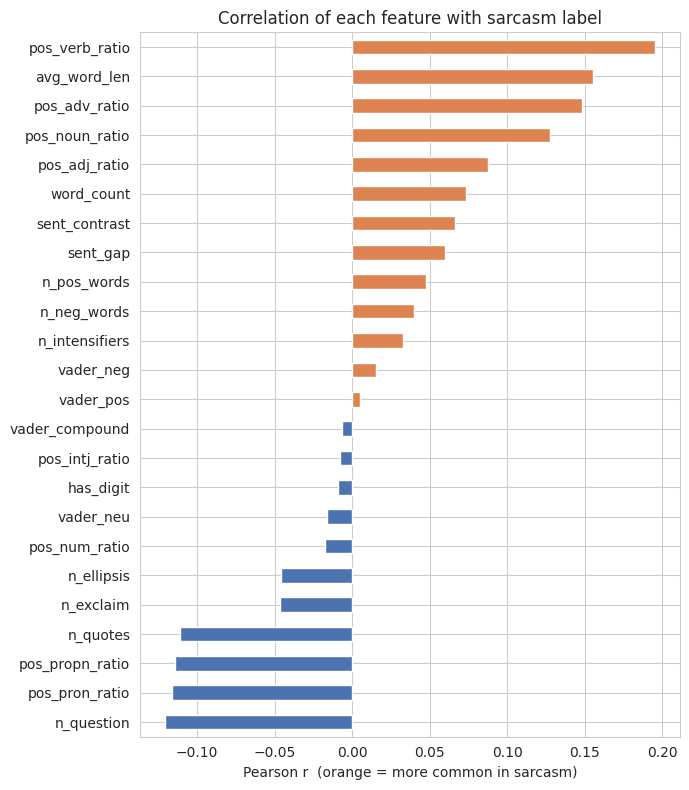

,Not sarcastic,Sarcastic
vader_pos,0.104,0.105
vader_neg,0.108,0.113
vader_neu,0.788,0.782
vader_compound,-0.011,-0.016
n_pos_words,0.472,0.539
n_neg_words,0.491,0.550
sent_contrast,0.119,0.164
sent_gap,0.567,0.730
pos_adj_ratio,0.086,0.103
pos_adv_ratio,0.026,0.045


In [27]:
# ============================ CELL 26 ===============================
# Which handcrafted features actually separate the classes?
comparison = handcrafted.groupby(df["is_sarcastic"]).mean().T
comparison.columns = ["Not sarcastic", "Sarcastic"]
corr = handcrafted.corrwith(df["is_sarcastic"]).sort_values()

plt.figure(figsize=(7, 8))
corr.plot(kind="barh", color=["#DD8452" if v > 0 else "#4C72B0" for v in corr])
plt.title("Correlation of each feature with sarcasm label")
plt.xlabel("Pearson r  (orange = more common in sarcasm)")
plt.tight_layout(); plt.show()
comparison.round(3)


In [28]:
# ============================ CELL 27 ===============================
# Feature group 4 - TF-IDF (fit on TRAIN only)
# TF  = how often a term appears in a headline (sublinear: 1 + log(tf))
# IDF = log(N / docs containing term) -> rare, distinctive terms weigh more
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=5000, min_df=2,
                        sublinear_tf=True, token_pattern=r"(?u)\b\w+\b|[!?]|\.\.\.")
X_tfidf_train = tfidf.fit_transform(df.loc[train_idx, "processed_text"])
X_tfidf_test  = tfidf.transform(df.loc[test_idx, "processed_text"])
print("TF-IDF shape (train):", X_tfidf_train.shape)

# Peek at the IDF weights: lowest = most common terms, highest = rarest
idf = pd.Series(tfidf.idf_, index=tfidf.get_feature_names_out()).sort_values()
print("\nLowest IDF (common):", list(idf.index[:10]))
print("Highest IDF (rare):  ", list(idf.index[-10:]))



TF-IDF shape (train): (22802, 5000)

Lowest IDF (common): ['not', 'trump', 'man', 'new', 'get', 'woman', 'how', 'year', '?', 'make']
Highest IDF (rare):   ['year life', 'xbox', 'drift', 'drilling', 'bra', 'lindsay', 'yelp', 'skyrocket', 'obsessive', 'attach']


In [29]:
# ============================ CELL 28 ===============================
# Compress TF-IDF with SVD (Latent Semantic Analysis): 5000 sparse dims -> 50 dense
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(n_components=50, random_state=SEED)
X_svd_train = svd.fit_transform(X_tfidf_train)
X_svd_test  = svd.transform(X_tfidf_test)
print(f"Variance kept by 50 components: {svd.explained_variance_ratio_.sum():.1%}")
# Low % is normal for short headlines - SVD here is a compact summary,
# the BiLSTM branch carries most of the word-level information.


Variance kept by 50 components: 9.0%


In [30]:
# ============================ CELL 29 ===============================
# Combine + scale (scaler fit on TRAIN only)
from sklearn.preprocessing import StandardScaler

X_feat_train = np.hstack([handcrafted.loc[train_idx].values, X_svd_train])
X_feat_test  = np.hstack([handcrafted.loc[test_idx].values,  X_svd_test])

scaler = StandardScaler()
X_feat_train = scaler.fit_transform(X_feat_train)
X_feat_test  = scaler.transform(X_feat_test)

FEATURE_NAMES = list(handcrafted.columns) + [f"svd_{i}" for i in range(50)]
print("Final NLP feature matrix:", X_feat_train.shape, X_feat_test.shape)


Final NLP feature matrix: (22802, 74) (5701, 74)


In [31]:
# ============================ CELL 30 ===============================
# Quick check: can the NLP features ALONE predict sarcasm?
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

n_hand = handcrafted.shape[1]
for name, cols in [("Handcrafted only", slice(0, n_hand)),
                   ("SVD only", slice(n_hand, None)),
                   ("All NLP features", slice(None))]:
    clf = LogisticRegression(max_iter=1000).fit(X_feat_train[:, cols], y_train)
    print(f"{name:<18} F1 = {f1_score(y_test, clf.predict(X_feat_test[:, cols])):.3f}")


Handcrafted only   F1 = 0.671
SVD only           F1 = 0.611
All NLP features   F1 = 0.721


In [32]:
# ============================ CELL 31 ===============================
# Save everything for Phases 5-7 and the Streamlit demo
import joblib
from scipy import sparse

np.save("features/X_feat_train.npy", X_feat_train); np.save("features/X_feat_test.npy", X_feat_test)
np.save("features/y_train.npy", y_train);           np.save("features/y_test.npy", y_test)
sparse.save_npz("features/X_tfidf_train.npz", X_tfidf_train)   # full TF-IDF for the Phase 6 baseline
sparse.save_npz("features/X_tfidf_test.npz",  X_tfidf_test)
joblib.dump({"tfidf": tfidf, "svd": svd, "scaler": scaler,
             "feature_names": FEATURE_NAMES}, "models/nlp_feature_pipeline.joblib")
print("Saved feature matrices, labels, split indices and fitted pipeline.")

# If you mounted Drive:
!cp features/*.npy features/*.npz models/nlp_feature_pipeline.joblib /content/drive/MyDrive/sarcasm_project/


Saved feature matrices, labels, split indices and fitted pipeline.


In [33]:
# =====================================================================
# SARCASM DETECTION - PHASE 5: Sequence Preparation for Deep Learning
# Add these cells BELOW cell 31 in the same Colab notebook.
#
# Turns clean_text into padded integer sequences + a GloVe embedding
# matrix (Branch A input). Uses the SAME train/test split as Phase 4.
# Note: Colab now ships Keras 3, which removed the old keras Tokenizer,
# so the vocabulary is built manually here (also easier to explain).
# =====================================================================


# ============================ CELL 32 ===============================
# Restore if the session restarted (re-run cells 1-2 first)
try:
    train_idx, df["clean_text"]
except (NameError, KeyError):
    df = pd.read_csv("data/sarcasm_preprocessed.csv")
    train_idx, test_idx = np.load("features/train_idx.npy"), np.load("features/test_idx.npy")
    y_train, y_test = np.load("features/y_train.npy"), np.load("features/y_test.npy")
print(f"Train: {len(train_idx)} | Test: {len(test_idx)}")


Train: 22802 | Test: 5701


In [34]:
# ============================ CELL 33 ===============================
# Tokenize clean_text (stop words KEPT - the BiLSTM needs full sentences)
# Possessive 's is split off to match how GloVe was tokenized ("man's" -> "man", "'s")
def dl_tokenize(text):
    return str(text).replace("'s", " 's").split()

train_tokens = [dl_tokenize(t) for t in df.loc[train_idx, "clean_text"]]
test_tokens  = [dl_tokenize(t) for t in df.loc[test_idx,  "clean_text"]]
print(train_tokens[0])


['gobbler', 'games', 'is', 'the', 'brutal', 'hunger', 'games', 'parody', 'you', 'need', 'to', 'see']


In [35]:
# ============================ CELL 34 ===============================
# Build vocabulary from TRAIN only
# index 0 = <PAD> (padding), index 1 = <OOV> (words never seen in training)
PAD, OOV = "<PAD>", "<OOV>"
word_counts = Counter(w for toks in train_tokens for w in toks)
word_index = {PAD: 0, OOV: 1}
for w, _ in word_counts.most_common():
    word_index[w] = len(word_index)
VOCAB_SIZE = len(word_index)

def to_ids(tokens):
    return [word_index.get(w, 1) for w in tokens]

seq_train = [to_ids(t) for t in train_tokens]
seq_test  = [to_ids(t) for t in test_tokens]

test_oov = sum(i == 1 for s in seq_test for i in s) / sum(len(s) for s in seq_test)
print(f"Vocabulary size: {VOCAB_SIZE}")
print(f"Test tokens unseen in training (OOV): {test_oov:.1%}")
print("Example:", train_tokens[0], "->", seq_train[0])


Vocabulary size: 23871
Test tokens unseen in training (OOV): 4.5%
Example: ['gobbler', 'games', 'is', 'the', 'brutal', 'hunger', 'games', 'parody', 'you', 'need', 'to', 'see'] -> [13283, 1233, 10, 4, 3853, 2169, 1233, 2627, 15, 172, 2, 191]


In [36]:
# ============================ CELL 35 ===============================
# Padding / truncation to a fixed length
from tensorflow.keras.utils import pad_sequences

lengths = [len(s) for s in seq_train]
MAX_LEN = int(np.percentile(lengths, 95))   # recomputed on final tokens
print(f"MAX_LEN = {MAX_LEN} | headlines truncated: {np.mean(np.array(lengths) > MAX_LEN):.1%}")

X_seq_train = pad_sequences(seq_train, maxlen=MAX_LEN, padding="post", truncating="post")
X_seq_test  = pad_sequences(seq_test,  maxlen=MAX_LEN, padding="post", truncating="post")
print("Shapes:", X_seq_train.shape, X_seq_test.shape)
print("Padded example:", X_seq_train[0])

MAX_LEN = 16 | headlines truncated: 4.5%
Shapes: (22802, 16) (5701, 16)
Padded example: [13283  1233    10     4  3853  2169  1233  2627    15   172     2   191
     0     0     0     0]


In [37]:
# ============================ CELL 36 ===============================
# Load GloVe vectors (only for words in our vocabulary - saves RAM)
EMBED_DIM = 100
glove = {}
with open("embeddings/glove.6B.100d.txt", encoding="utf8") as f:
    for line in tqdm(f, total=400000, desc="Reading GloVe"):
        word, *vec = line.rstrip().split(" ")
        if word in word_index:
            glove[word] = np.asarray(vec, dtype="float32")
print(f"Found GloVe vectors for {len(glove)} of {VOCAB_SIZE} vocab words")


Reading GloVe:   0%|          | 0/400000 [00:00<?, ?it/s]

Found GloVe vectors for 23053 of 23871 vocab words


In [38]:
# ============================ CELL 37 ===============================
# Build the embedding matrix: row i = vector for the word with id i
# PAD -> zeros; words missing from GloVe -> small random vectors (learnable later)
all_vecs = np.stack(list(glove.values()))
rng = np.random.default_rng(SEED)
embedding_matrix = rng.normal(all_vecs.mean(), all_vecs.std(),
                              (VOCAB_SIZE, EMBED_DIM)).astype("float32")
embedding_matrix[0] = 0.0
missing = []
for w, i in word_index.items():
    if w in glove:
        embedding_matrix[i] = glove[w]
    elif i > 1:
        missing.append(w)

token_cov = sum(c for w, c in word_counts.items() if w in glove) / sum(word_counts.values())
print(f"Embedding matrix: {embedding_matrix.shape}")
print(f"Vocab coverage: {len(glove) / VOCAB_SIZE:.1%} | token coverage: {token_cov:.1%}")
print("Most frequent words missing from GloVe:",
      [w for w, _ in word_counts.most_common() if w in set(missing)][:15])


Embedding matrix: (23871, 100)
Vocab coverage: 96.6% | token coverage: 99.6%
Most frequent words missing from GloVe: ['huffpollster', 'nsfw', 'selfie', 'daca', 'reince', 'disick', 'brexit', 'trumpcare', 'shits', 'emoji', 'metoo', 'blasey', 'shkreli', 'shithole', 'kimye']


In [39]:
# ============================ CELL 38 ===============================
# Embedding insight for the report: why sarcasm fools word vectors
# GloVe learns from context, and "great"/"terrible" appear in the same contexts,
# so opposite sentiments can sit close together in vector space.
def cosine(a, b):
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))

pairs = [("good", "bad"), ("great", "terrible"), ("love", "hate"),
         ("love", "adore"), ("great", "banana")]
for a, b in pairs:
    if a in glove and b in glove:
        print(f"cos({a}, {b}) = {cosine(glove[a], glove[b]):.2f}")
# Expect antonyms to score surprisingly high - static embeddings miss tone,
# which is why we add the BiLSTM (context) and the VADER features (polarity).



cos(good, bad) = 0.77
cos(great, terrible) = 0.57
cos(love, hate) = 0.57
cos(love, adore) = 0.40
cos(great, banana) = 0.16


In [40]:
# ============================ CELL 39 ===============================
# Alignment check: sequences and NLP features must describe the same rows
X_feat_train = np.load("features/X_feat_train.npy") if "X_feat_train" not in globals() else X_feat_train
X_feat_test  = np.load("features/X_feat_test.npy")  if "X_feat_test"  not in globals() else X_feat_test
assert len(X_seq_train) == len(X_feat_train) == len(y_train)
assert len(X_seq_test)  == len(X_feat_test)  == len(y_test)
print("Branch A (sequences):", X_seq_train.shape, "| Branch B (NLP features):", X_feat_train.shape)



Branch A (sequences): (22802, 16) | Branch B (NLP features): (22802, 74)


In [41]:
# ============================ CELL 40 ===============================
# Save for Phase 7 and the demo
import pickle

np.save("features/X_seq_train.npy", X_seq_train); np.save("features/X_seq_test.npy", X_seq_test)
np.save("embeddings/embedding_matrix.npy", embedding_matrix)
with open("models/dl_vocab.pkl", "wb") as f:
    pickle.dump({"word_index": word_index, "max_len": MAX_LEN, "embed_dim": EMBED_DIM}, f)
del glove, all_vecs   # free RAM before training
print("Saved sequences, embedding matrix and vocabulary.")

# If you mounted Drive:
!cp features/X_seq_*.npy embeddings/embedding_matrix.npy models/dl_vocab.pkl /content/drive/MyDrive/sarcasm_project/


Saved sequences, embedding matrix and vocabulary.


In [42]:
# =====================================================================
# SARCASM DETECTION - PHASE 6: Classic NLP Baseline (TF-IDF + ML)
# Add these cells BELOW cell 40 in the same Colab notebook.
#
# Gives the score your hybrid deep learning model must beat.
# Uses the full TF-IDF matrix from Phase 4 (same train/test split).
# =====================================================================


# ============================ CELL 41 ===============================
# Restore if the session restarted (re-run cells 1-2 first)
import json, joblib
from scipy import sparse

X_tfidf_train = sparse.load_npz("features/X_tfidf_train.npz")
X_tfidf_test  = sparse.load_npz("features/X_tfidf_test.npz")
y_train, y_test = np.load("features/y_train.npy"), np.load("features/y_test.npy")
test_idx = np.load("features/test_idx.npy")
tfidf = joblib.load("models/nlp_feature_pipeline.joblib")["tfidf"]
try:
    df["clean_text"]
except (NameError, KeyError):
    df = pd.read_csv("data/sarcasm_preprocessed.csv")
print("TF-IDF train/test:", X_tfidf_train.shape, X_tfidf_test.shape)


TF-IDF train/test: (22802, 5000) (5701, 5000)


In [43]:
# ============================ CELL 42 ===============================
# Logistic Regression with a small hyperparameter search (5-fold CV on TRAIN)
# C = inverse regularization strength: smaller C = simpler model
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(LogisticRegression(max_iter=2000, solver="liblinear"),
                    {"C": [0.5, 1, 2, 5, 10]}, scoring="f1", cv=5, n_jobs=-1)
grid.fit(X_tfidf_train, y_train)
best_lr = grid.best_estimator_
print("Best C:", grid.best_params_["C"], "| CV F1:", round(grid.best_score_, 4))


Best C: 5 | CV F1: 0.7829


In [44]:
# ============================ CELL 43 ===============================
# Compare three classic classifiers on the TEST set
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

def score(y_true, y_pred):
    return {"accuracy":  accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred),
            "recall":    recall_score(y_true, y_pred),
            "f1":        f1_score(y_true, y_pred)}

baselines = {
    "Naive Bayes":         MultinomialNB(alpha=0.5).fit(X_tfidf_train, y_train),
    "Linear SVM":          LinearSVC(C=0.5).fit(X_tfidf_train, y_train),
    "Logistic Regression": best_lr,
}
results = {name: score(y_test, m.predict(X_tfidf_test)) for name, m in baselines.items()}
pd.DataFrame(results).T.round(4)


,accuracy,precision,recall,f1
Naive Bayes,0.7899,0.7893,0.7613,0.7751
Linear SVM,0.7911,0.7859,0.7706,0.7782
Logistic Regression,0.7899,0.7832,0.7717,0.7774


               precision    recall  f1-score   support

Not sarcastic       0.80      0.81      0.80      2990
    Sarcastic       0.78      0.77      0.78      2711

     accuracy                           0.79      5701
    macro avg       0.79      0.79      0.79      5701
 weighted avg       0.79      0.79      0.79      5701



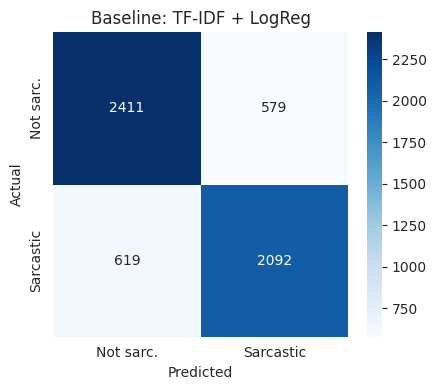

In [45]:
# ============================ CELL 44 ===============================
# Detailed report + confusion matrix for the Logistic Regression baseline
y_pred_lr = best_lr.predict(X_tfidf_test)
print(classification_report(y_test, y_pred_lr, target_names=["Not sarcastic", "Sarcastic"]))

cm = confusion_matrix(y_test, y_pred_lr)
plt.figure(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not sarc.", "Sarcastic"], yticklabels=["Not sarc.", "Sarcastic"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Baseline: TF-IDF + LogReg")
plt.tight_layout(); plt.show()


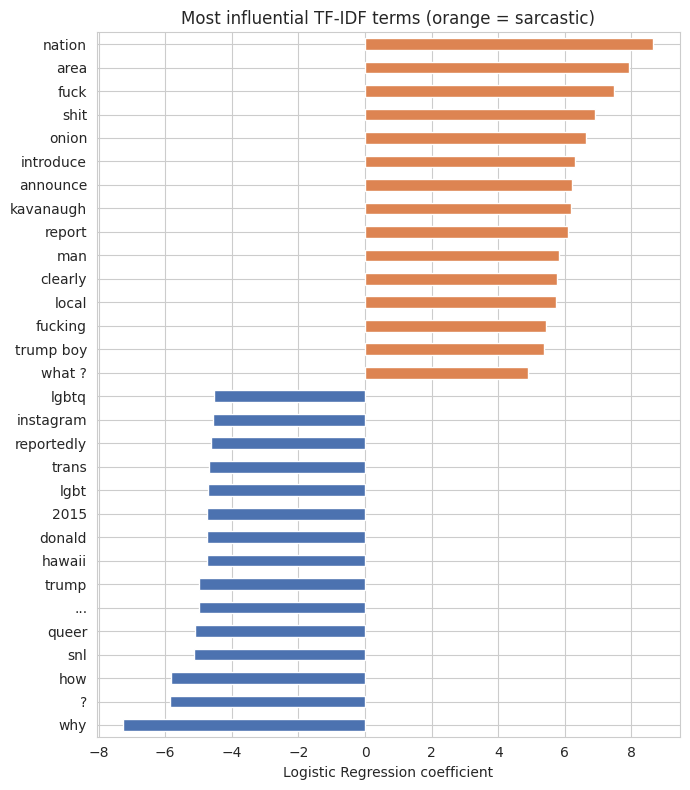

In [46]:
# ============================ CELL 45 ===============================
# What did the baseline learn? Top n-grams by coefficient
# Positive weight -> pushes towards sarcastic, negative -> towards not sarcastic
coefs = pd.Series(best_lr.coef_[0], index=tfidf.get_feature_names_out()).sort_values()
top = pd.concat([coefs.head(15), coefs.tail(15)])

plt.figure(figsize=(7, 8))
top.plot(kind="barh", color=["#4C72B0" if v < 0 else "#DD8452" for v in top])
plt.title("Most influential TF-IDF terms (orange = sarcastic)")
plt.xlabel("Logistic Regression coefficient")
plt.tight_layout(); plt.show()


In [47]:
# ============================ CELL 46 ===============================
# Error analysis: confident mistakes show what bag-of-words cannot capture
proba = best_lr.predict_proba(X_tfidf_test)[:, 1]
errors = pd.DataFrame({"headline": df.loc[test_idx, "headline"].values,
                       "actual": y_test, "p_sarcastic": proba.round(3)})
errors = errors[(errors.p_sarcastic >= 0.5) != (errors.actual == 1)]
errors["confidence"] = (errors.p_sarcastic - 0.5).abs()

print(f"Misclassified: {len(errors)} of {len(y_test)}\n")
print("== Sarcastic headlines the baseline MISSED (false negatives) ==")
for _, r in errors[errors.actual == 1].nlargest(5, "confidence").iterrows():
    print(f"  p={r.p_sarcastic:.2f}  {r.headline}")
print("\n== Normal headlines flagged as sarcastic (false positives) ==")
for _, r in errors[errors.actual == 0].nlargest(5, "confidence").iterrows():
    print(f"  p={r.p_sarcastic:.2f}  {r.headline}")


Misclassified: 1198 of 5701

== Sarcastic headlines the baseline MISSED (false negatives) ==
  p=0.00  women: why don't they lose some weight?
  p=0.00  'why can i never seem to say the right thing?' weeps trump into pillow
  p=0.00  trump retweets video from anti-muslim hate group
  p=0.01  'you are donald trump, 45th president of the united states,' trump reads from faded tattoo on wrist
  p=0.01  christianity: is your family at risk?

== Normal headlines flagged as sarcastic (false positives) ==
  p=0.99  men behaving badly
  p=0.98  we tested the new 'tearless' onions to see if they really work
  p=0.98  defiant londoners sit in the street for ramadan evening meal after high-rise fire
  p=0.97  mitt romney 'planning to run' for senate if orrin hatch retires: report
  p=0.97  traditional campaign tactics are basically a waste of time, new study concludes


In [48]:

# ============================ CELL 47 ===============================
# Save the baseline scores for the final comparison table (Phase 9)
all_results = {f"Baseline - {k}": v for k, v in results.items()}
with open("results/results.json", "w") as f:
    json.dump(all_results, f, indent=2)
joblib.dump(best_lr, "models/baseline_logreg.joblib")
print(f"Baseline to beat -> F1 = {results['Logistic Regression']['f1']:.4f}")

# If you mounted Drive:
!cp results/results.json models/baseline_logreg.joblib /content/drive/MyDrive/sarcasm_project/


Baseline to beat -> F1 = 0.7774


In [49]:
# =====================================================================
# SARCASM DETECTION - PHASE 7: Build the Hybrid Model
# Add these cells BELOW cell 47 in the same Colab notebook.
#
#   Branch A (DL):  sequence -> GloVe Embedding -> BiLSTM -> Attention
#   Branch B (NLP): handcrafted + TF-IDF/SVD features -> Dense
#   Merge:          Concatenate -> Dense -> Dropout -> Sigmoid
#
# Training happens in Phase 8; this phase builds and sanity-checks the model.
# =====================================================================


# ============================ CELL 48 ===============================
# Restore if the session restarted (re-run cells 1-2 first)
import pickle
import keras
from keras import layers, ops

X_seq_train, X_seq_test   = np.load("features/X_seq_train.npy"), np.load("features/X_seq_test.npy")
X_feat_train, X_feat_test = np.load("features/X_feat_train.npy"), np.load("features/X_feat_test.npy")
y_train, y_test           = np.load("features/y_train.npy"), np.load("features/y_test.npy")
embedding_matrix          = np.load("embeddings/embedding_matrix.npy")
with open("models/dl_vocab.pkl", "rb") as f:
    vocab_info = pickle.load(f)

VOCAB_SIZE, EMBED_DIM = embedding_matrix.shape
MAX_LEN = vocab_info["max_len"]
N_FEATURES = X_feat_train.shape[1]
print(f"VOCAB_SIZE={VOCAB_SIZE} | EMBED_DIM={EMBED_DIM} | MAX_LEN={MAX_LEN} | N_FEATURES={N_FEATURES}")


VOCAB_SIZE=23871 | EMBED_DIM=100 | MAX_LEN=16 | N_FEATURES=74


In [50]:
# ============================ CELL 49 ===============================
# Custom attention layer (additive / Bahdanau-style attention pooling)
#   score_t  = u . tanh(W h_t + b)       how important is word t?
#   alpha_t  = softmax(score_t)          importance weights, sum to 1
#   context  = sum_t alpha_t * h_t       weighted summary of the sentence
# Padding positions get weight 0 via the mask, so they never get attention.
@keras.saving.register_keras_serializable()
class AttentionPooling(layers.Layer):
    def __init__(self, units=64, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.supports_masking = True

    def build(self, input_shape):
        d = input_shape[-1]
        self.W = self.add_weight(name="W", shape=(d, self.units), initializer="glorot_uniform")
        self.b = self.add_weight(name="b", shape=(self.units,), initializer="zeros")
        self.u = self.add_weight(name="u", shape=(self.units, 1), initializer="glorot_uniform")

    def call(self, h, mask=None):
        score = ops.squeeze(ops.matmul(ops.tanh(ops.matmul(h, self.W) + self.b), self.u), -1)
        if mask is not None:
            score = ops.where(mask, score, ops.full_like(score, -1e9))
        alpha = ops.softmax(score, axis=-1)
        context = ops.sum(h * ops.expand_dims(alpha, -1), axis=1)
        return context, alpha

    def compute_mask(self, inputs, mask=None):
        return [None, None]   # outputs have no time dimension any more

    def get_config(self):
        return {**super().get_config(), "units": self.units}

In [51]:
# ============================ CELL 50 ===============================
# Model builder - flags let you build the DL-only version too (optional ablation)
def build_model(use_text=True, use_features=True,
                lstm_units=64, att_units=64, train_embeddings=False, lr=1e-3):
    inputs, branches = [], []

    if use_text:                                   # ---- Branch A: deep learning ----
        seq_in = keras.Input(shape=(MAX_LEN,), dtype="int32", name="text_seq")
        x = layers.Embedding(
            VOCAB_SIZE, EMBED_DIM, mask_zero=True, trainable=train_embeddings,
            embeddings_initializer=keras.initializers.Constant(embedding_matrix),
            name="glove_embedding")(seq_in)
        x = layers.SpatialDropout1D(0.2, name="embed_dropout")(x)
        x = layers.Bidirectional(layers.LSTM(lstm_units, return_sequences=True),
                                 name="bilstm")(x)
        context, alpha = AttentionPooling(att_units, name="attention")(x)
        inputs.append(seq_in); branches.append(context)

    if use_features:                               # ---- Branch B: NLP features ----
        feat_in = keras.Input(shape=(N_FEATURES,), name="nlp_features")
        f = layers.Dense(32, activation="relu", name="feat_dense")(feat_in)
        f = layers.Dropout(0.3, name="feat_dropout")(f)
        inputs.append(feat_in); branches.append(f)

    merged = layers.Concatenate(name="merge")(branches) if len(branches) > 1 else branches[0]
    z = layers.Dense(64, activation="relu", name="fusion_dense")(merged)
    z = layers.Dropout(0.5, name="fusion_dropout")(z)
    out = layers.Dense(1, activation="sigmoid", name="sarcasm_prob")(z)

    name = "hybrid" if (use_text and use_features) else ("dl_only" if use_text else "features_only")
    model = keras.Model(inputs, out, name=name)
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="binary_crossentropy",
                  metrics=["accuracy",
                           keras.metrics.Precision(name="precision"),
                           keras.metrics.Recall(name="recall"),
                           keras.metrics.AUC(name="auc")])

    # Side model that outputs attention weights - used for heatmaps in Phase 9
    att_model = keras.Model(inputs, alpha, name="attention_viewer") if use_text else None
    return model, att_model


In [52]:
# ============================ CELL 51 ===============================
# Build the hybrid model
keras.utils.set_random_seed(SEED)
model, att_model = build_model()
model.summary()
# Expect a large "non-trainable" count: that's the frozen GloVe matrix.
# Trainable params should be roughly 100-150k.


Model: "hybrid"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text_seq            │ (None, 16)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ glove_embedding     │ (None, 16, 100)   │  2,387,100 │ text_seq[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embed_dropout       │ (None, 16, 100)   │          0 │ glove_embedding[… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 16)        │          0 │ text_seq[0][0]    │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ nlp_features        │ (None, 74)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bilstm              │ (None, 16, 128)   │     84,480 │ embed_dropout[0]… │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feat_dense (Dense)  │ (None, 32)        │      2,400 │ nlp_features[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ [(None, 128),     │      8,320 │ bilstm[0][0],     │
│ (AttentionPooling)  │ (None, 16)]       │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feat_dropout        │ (None, 32)        │          0 │ feat_dense[0][0]  │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ merge (Concatenate) │ (None, 160)       │          0 │ attention[0][0],  │
│                     │                   │            │ feat_dropout[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_dense        │ (None, 64)        │     10,304 │ merge[0][0]       │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_dropout      │ (None, 64)        │          0 │ fusion_dense[0][… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sarcasm_prob        │ (None, 1)         │         65 │ fusion_dropout[0… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,492,669 (9.51 MB)

 Trainable params: 105,569 (412.38 KB)

 Non-trainable params: 2,387,100 (9.11 MB)

In [53]:
# ============================ CELL 53 ===============================
# Sanity checks before spending time on training
sample_seq, sample_feat = X_seq_train[:4], X_feat_train[:4]
probs = model.predict([sample_seq, sample_feat], verbose=0)
alphas = att_model.predict([sample_seq, sample_feat], verbose=0)

print("Output shape:", probs.shape, "| untrained probs:", probs.ravel().round(3))
print("Attention weights sum to 1:", np.allclose(alphas.sum(axis=1), 1, atol=1e-4))
pad_weight = alphas[sample_seq == 0].sum()
print(f"Total attention on padding tokens: {pad_weight:.6f}  (should be ~0)")

# Untrained loss should be close to ln(2) = 0.693 for a balanced binary task
loss = model.evaluate([X_seq_train[:256], X_feat_train[:256]], y_train[:256], verbose=0)[0]
print(f"Untrained loss: {loss:.3f}  (expected ~0.69)")

Output shape: (4, 1) | untrained probs: [0.311 0.559 0.326 0.516]
Attention weights sum to 1: True
Total attention on padding tokens: 0.000000  (should be ~0)
Untrained loss: 0.741  (expected ~0.69)


In [54]:
# =====================================================================
# SARCASM DETECTION - PHASE 8: Training
# Add these cells BELOW cell 53 in the same Colab notebook.
# Make sure the runtime is on GPU (T4): roughly 10-20 s per epoch.
#
# Plan:  1) train with frozen GloVe + early stopping
#        2) optional short fine-tune with GloVe unfrozen (kept only if it helps)
#        3) tune the decision threshold on validation data
#        4) save everything for Phase 9
# The TEST set is not touched in this phase.
# =====================================================================


# ============================ CELL 54 ===============================
# Restore if the session restarted: re-run cells 1-2 and 48-50 first, then this
import time, json
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

try:
    model
except NameError:
    keras.utils.set_random_seed(SEED)
    model, att_model = build_model()
print("GPU:", tf.config.list_physical_devices("GPU") or "None - training will be slow")


GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [55]:
# ============================ CELL 55 ===============================
# Validation split carved out of TRAIN (stratified) - used for early stopping
# and threshold tuning, so the test set stays completely unseen.
(Xs_tr, Xs_val, Xf_tr, Xf_val, y_tr, y_val) = train_test_split(
    X_seq_train, X_feat_train, y_train,
    test_size=0.1, stratify=y_train, random_state=SEED)
print(f"Train: {len(y_tr)} | Validation: {len(y_val)} | Test (untouched): {len(y_test)}")



Train: 20521 | Validation: 2281 | Test (untouched): 5701


In [56]:
# ============================ CELL 56 ===============================
# Callbacks
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                  restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                      patience=1, min_lr=1e-5, verbose=1),
    keras.callbacks.ModelCheckpoint("models/hybrid_best.keras", monitor="val_loss",
                                    save_best_only=True, verbose=0),
]


In [57]:
# ============================ CELL 57 ===============================
# Stage 1: train with frozen GloVe embeddings
EPOCHS, BATCH = 20, 64
start = time.time()
history = model.fit(
    [Xs_tr, Xf_tr], y_tr,
    validation_data=([Xs_val, Xf_val], y_val),
    epochs=EPOCHS, batch_size=BATCH, callbacks=callbacks, verbose=1)
print(f"\nStage 1 done in {(time.time() - start) / 60:.1f} min, "
      f"best epoch = {int(np.argmin(history.history['val_loss'])) + 1}")



Epoch 1/20
321/321 ━━━━━━━━━━━━━━━━━━━━ 17s 31ms/step - accuracy: 0.7026 - auc: 0.7818 - loss: 0.5577 - precision: 0.6926 - recall: 0.6733 - val_accuracy: 0.8062 - val_auc: 0.8903 - val_loss: 0.4267 - val_precision: 0.7739 - val_recall: 0.8367 - learning_rate: 0.0010
Epoch 2/20
321/321 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.8050 - auc: 0.8860 - loss: 0.4260 - precision: 0.7961 - recall: 0.7930 - val_accuracy: 0.8317 - val_auc: 0.9123 - val_loss: 0.3786 - val_precision: 0.8081 - val_recall: 0.8469 - learning_rate: 0.0010
Epoch 3/20
321/321 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - accuracy: 0.8324 - auc: 0.9131 - loss: 0.3742 - precision: 0.8258 - recall: 0.8206 - val_accuracy: 0.8448 - val_auc: 0.9265 - val_loss: 0.3467 - val_precision: 0.8271 - val_recall: 0.8515 - learning_rate: 0.0010
Epoch 4/20
321/321 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.8522 - auc: 0.9315 - loss: 0.3339 - precision: 0.8445 - recall: 0.8445 - val_accuracy: 0.8575 - val_auc: 0.9341 - val_loss: 0.3293 

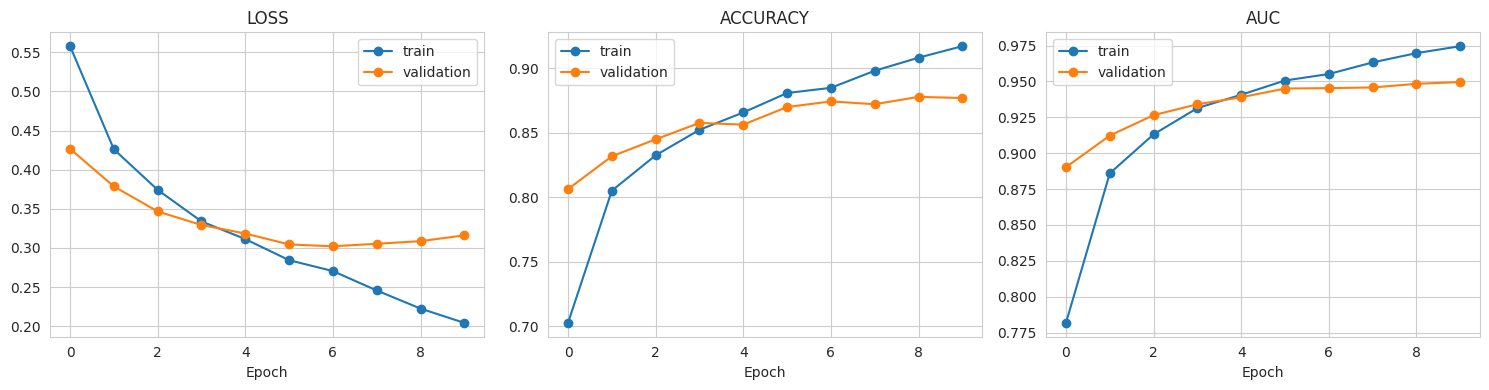

In [58]:
# ============================ CELL 58 ===============================
# Learning curves - include these in your report
h = history.history
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ["loss", "accuracy", "auc"]):
    ax.plot(h[metric], marker="o", label="train")
    ax.plot(h[f"val_{metric}"], marker="o", label="validation")
    ax.set_title(metric.upper()); ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout(); plt.savefig("results/figures/learning_curves.png", dpi=120); plt.show()
# Reading the curves: train loss falling while val loss rises = overfitting;
# early stopping already rolled back to the best validation epoch.


In [59]:
# ============================ CELL 59 ===============================
# Stage 2 (optional): fine-tune with GloVe unfrozen at a small learning rate.
# Lets word vectors adapt to sarcasm, e.g. "great" learns a sarcastic shade.
# Kept ONLY if validation loss improves; otherwise weights are rolled back.
FINE_TUNE = True

if FINE_TUNE:
    stage1_val_loss = model.evaluate([Xs_val, Xf_val], y_val, verbose=0)[0]
    stage1_weights = model.get_weights()

    model.get_layer("glove_embedding").trainable = True
    model.compile(optimizer=keras.optimizers.Adam(1e-4), loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.Precision(name="precision"),
                           keras.metrics.Recall(name="recall"), keras.metrics.AUC(name="auc")])
    ft_history = model.fit(
        [Xs_tr, Xf_tr], y_tr, validation_data=([Xs_val, Xf_val], y_val),
        epochs=4, batch_size=BATCH, verbose=1,
        callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=1,
                                                 restore_best_weights=True)])
    stage2_val_loss = model.evaluate([Xs_val, Xf_val], y_val, verbose=0)[0]

    if stage2_val_loss < stage1_val_loss:
        print(f"Fine-tuning helped: val loss {stage1_val_loss:.4f} -> {stage2_val_loss:.4f} (kept)")
        EMBEDDINGS = "fine-tuned"
    else:
        model.set_weights(stage1_weights)
        model.get_layer("glove_embedding").trainable = False
        print(f"Fine-tuning did not help ({stage2_val_loss:.4f} vs {stage1_val_loss:.4f}) - rolled back")
        EMBEDDINGS = "frozen"
else:
    EMBEDDINGS = "frozen"


Epoch 1/4
321/321 ━━━━━━━━━━━━━━━━━━━━ 11s 18ms/step - accuracy: 0.9039 - auc: 0.9669 - loss: 0.2340 - precision: 0.8981 - recall: 0.9000 - val_accuracy: 0.8772 - val_auc: 0.9502 - val_loss: 0.2952 - val_precision: 0.8609 - val_recall: 0.8847
Epoch 2/4
321/321 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.9088 - auc: 0.9702 - loss: 0.2212 - precision: 0.9065 - recall: 0.9011 - val_accuracy: 0.8794 - val_auc: 0.9507 - val_loss: 0.2963 - val_precision: 0.8641 - val_recall: 0.8856
Fine-tuning helped: val loss 0.3022 -> 0.2952 (kept)


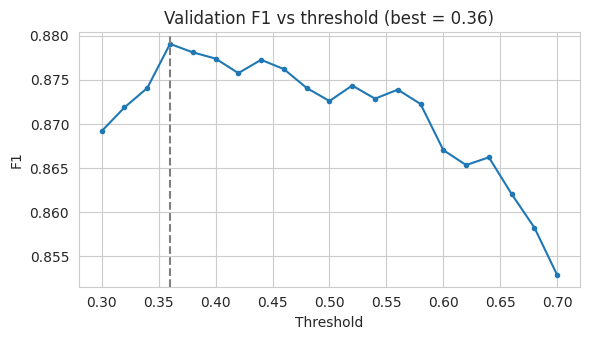

Val F1 @0.50 = 0.8726 | @0.36 = 0.8791


In [60]:
# ============================ CELL 60 ===============================
# Tune the decision threshold on VALIDATION data (default 0.5 is not always best)
val_probs = model.predict([Xs_val, Xf_val], verbose=0).ravel()
thresholds = np.arange(0.30, 0.71, 0.02)
val_f1s = [f1_score(y_val, (val_probs >= t).astype(int)) for t in thresholds]
BEST_THRESHOLD = float(thresholds[int(np.argmax(val_f1s))])

plt.figure(figsize=(6, 3.5))
plt.plot(thresholds, val_f1s, marker=".")
plt.axvline(BEST_THRESHOLD, ls="--", c="gray")
plt.title(f"Validation F1 vs threshold (best = {BEST_THRESHOLD:.2f})")
plt.xlabel("Threshold"); plt.ylabel("F1"); plt.tight_layout(); plt.show()
print(f"Val F1 @0.50 = {f1_score(y_val, (val_probs >= 0.5).astype(int)):.4f} | "
      f"@{BEST_THRESHOLD:.2f} = {max(val_f1s):.4f}")


In [61]:
# ============================ CELL 61 ===============================
# Optional ablation: DL-only model (no NLP features) - shows what Branch B adds
RUN_ABLATION = False   # set True if you have ~5 spare minutes

if RUN_ABLATION:
    keras.utils.set_random_seed(SEED)
    dl_model, _ = build_model(use_features=False)
    dl_model.fit(Xs_tr, y_tr, validation_data=(Xs_val, y_val), epochs=EPOCHS,
                 batch_size=BATCH, verbose=0,
                 callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                                          restore_best_weights=True)])
    dl_model.save("models/dl_only_model.keras")
    print("DL-only val F1 :", round(f1_score(y_val, (dl_model.predict(Xs_val, verbose=0).ravel() >= 0.5).astype(int)), 4))
    print("Hybrid  val F1 :", round(f1_score(y_val, (val_probs >= 0.5).astype(int)), 4))


In [63]:
# ============================ CELL 62 ===============================
# Save the final model + training info for Phase 9 and the demo
model.save("models/hybrid_final.keras")
with open("models/training_info.json", "w") as f:
    json.dump({"best_threshold": BEST_THRESHOLD, "embeddings": EMBEDDINGS,
               "epochs_trained": len(history.history["loss"]),
               "history": {k: [float(v) for v in vals] for k, vals in history.history.items()}},
              f, indent=2)
print(f"Saved models/hybrid_final.keras | threshold = {BEST_THRESHOLD:.2f} | embeddings = {EMBEDDINGS}")

# If you mounted Drive:
!cp models/hybrid_final.keras models/training_info.json results/figures/learning_curves.png /content/drive/MyDrive/sarcasm_project/


Saved hybrid_final.keras | threshold = 0.36 | embeddings = fine-tuned


In [64]:
# =====================================================================
# SARCASM DETECTION - PHASE 9: Final Evaluation on the TEST set
# Add these cells BELOW cell 62 in the same Colab notebook.
#
# First and only time the test set is used for the hybrid model.
# Produces: final comparison table, confusion matrices, ROC curves,
# attention heatmaps, error analysis, NLP feature importance, significance test.
# =====================================================================


# ============================ CELL 63 ===============================
# Restore everything (if restarted: re-run cells 1-2 and 49 first,
# cell 49 defines the custom AttentionPooling layer needed to load the model)
import json, pickle, joblib, os
import keras
import tensorflow as tf
from scipy import sparse
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, classification_report, confusion_matrix)

model = keras.models.load_model("models/hybrid_final.keras")
att_model = keras.Model(model.inputs, model.get_layer("attention").output[1])

X_seq_test, X_feat_test = np.load("features/X_seq_test.npy"), np.load("features/X_feat_test.npy")
y_test, test_idx = np.load("features/y_test.npy"), np.load("features/test_idx.npy")
X_tfidf_test = sparse.load_npz("features/X_tfidf_test.npz")
baseline = joblib.load("models/baseline_logreg.joblib")
FEATURE_NAMES = joblib.load("models/nlp_feature_pipeline.joblib")["feature_names"]
with open("models/dl_vocab.pkl", "rb") as f:
    index_word = {i: w for w, i in pickle.load(f)["word_index"].items()}
with open("models/training_info.json") as f:
    BEST_THRESHOLD = json.load(f)["best_threshold"]
with open("results/results.json") as f:
    all_results = json.load(f)
try:
    df["headline"]
except (NameError, KeyError):
    df = pd.read_csv("data/sarcasm_preprocessed.csv")
test_headlines = df.loc[test_idx, "headline"].values
print(f"Test set: {len(y_test)} headlines | tuned threshold = {BEST_THRESHOLD:.2f}")


Test set: 5701 headlines | tuned threshold = 0.36


In [65]:
# ============================ CELL 64 ===============================
# Test-set scores: hybrid at 0.50 and at the tuned threshold
def score(y_true, y_pred, y_prob=None):
    s = {"accuracy": accuracy_score(y_true, y_pred), "precision": precision_score(y_true, y_pred),
         "recall": recall_score(y_true, y_pred), "f1": f1_score(y_true, y_pred)}
    if y_prob is not None:
        s["roc_auc"] = roc_auc_score(y_true, y_prob)
    return s

p_hybrid = model.predict([X_seq_test, X_feat_test], verbose=0).ravel()
p_base   = baseline.predict_proba(X_tfidf_test)[:, 1]
pred_hybrid = (p_hybrid >= 0.5).astype(int)
pred_base   = (p_base   >= 0.5).astype(int)

all_results["Baseline - Logistic Regression"]["roc_auc"] = roc_auc_score(y_test, p_base)
all_results["Hybrid BiLSTM+Attention+NLP (t=0.50)"] = score(y_test, pred_hybrid, p_hybrid)
all_results[f"Hybrid BiLSTM+Attention+NLP (t={BEST_THRESHOLD:.2f})"] = score(
    y_test, (p_hybrid >= BEST_THRESHOLD).astype(int), p_hybrid)

if os.path.exists("models/dl_only_model.keras"):            # only if you ran the ablation
    dl_model = keras.models.load_model("models/dl_only_model.keras")
    p_dl = dl_model.predict(X_seq_test, verbose=0).ravel()
    all_results["DL only - BiLSTM+Attention (t=0.50)"] = score(y_test, (p_dl >= 0.5).astype(int), p_dl)


,accuracy,precision,recall,f1,roc_auc
Baseline - Naive Bayes,0.7899,0.7893,0.7613,0.7751,NaN
Baseline - Logistic Regression,0.7899,0.7832,0.7717,0.7774,0.8779
Baseline - Linear SVM,0.7911,0.7859,0.7706,0.7782,NaN
Hybrid BiLSTM+Attention+NLP (t=0.50),0.8677,0.8713,0.8469,0.8590,0.9428
Hybrid BiLSTM+Attention+NLP (t=0.36),0.8684,0.8420,0.8904,0.8655,0.9428


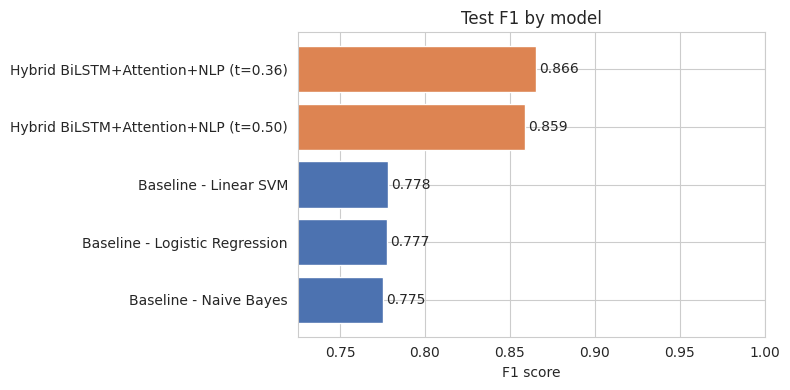

Hybrid vs TF-IDF baseline: +0.0816 F1


In [66]:
# ============================ CELL 65 ===============================
# THE final comparison table + F1 chart (main result of the project)
results_df = pd.DataFrame(all_results).T[["accuracy", "precision", "recall", "f1", "roc_auc"]]
results_df = results_df.sort_values("f1")
display(results_df.round(4))

plt.figure(figsize=(8, 0.6 * len(results_df) + 1))
colors = ["#DD8452" if "Hybrid" in n else "#8DA0CB" if "DL" in n else "#4C72B0"
          for n in results_df.index]
plt.barh(results_df.index, results_df["f1"], color=colors)
for i, v in enumerate(results_df["f1"]):
    plt.text(v + 0.002, i, f"{v:.3f}", va="center")
plt.xlim(results_df["f1"].min() - 0.05, 1.0)
plt.title("Test F1 by model"); plt.xlabel("F1 score")
plt.tight_layout(); plt.savefig("results/figures/model_comparison.png", dpi=120); plt.show()

gain = all_results["Hybrid BiLSTM+Attention+NLP (t=0.50)"]["f1"] - all_results["Baseline - Logistic Regression"]["f1"]
print(f"Hybrid vs TF-IDF baseline: {gain:+.4f} F1")



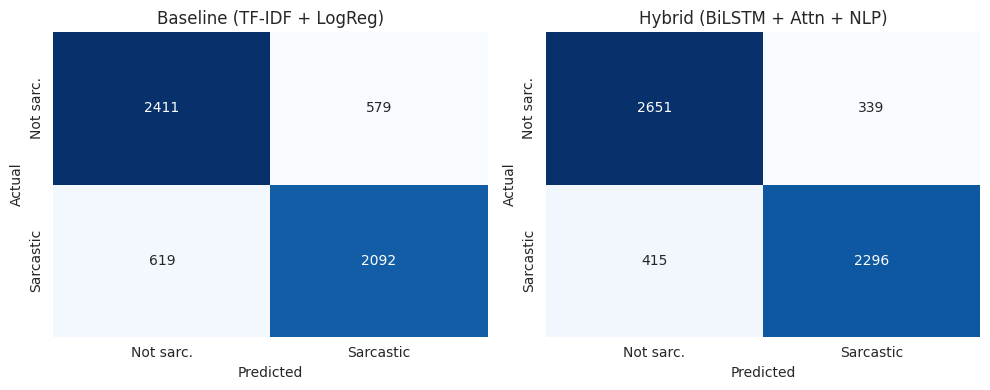

Hybrid model (threshold 0.50):
               precision    recall  f1-score   support

Not sarcastic     0.8646    0.8866    0.8755      2990
    Sarcastic     0.8713    0.8469    0.8590      2711

     accuracy                         0.8677      5701
    macro avg     0.8680    0.8668    0.8672      5701
 weighted avg     0.8678    0.8677    0.8676      5701



In [67]:
# ============================ CELL 66 ===============================
# Confusion matrices side by side + classification report
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
labels = ["Not sarc.", "Sarcastic"]
for ax, (name, pred) in zip(axes, [("Baseline (TF-IDF + LogReg)", pred_base),
                                   ("Hybrid (BiLSTM + Attn + NLP)", pred_hybrid)]):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues",
                xticklabels=labels, yticklabels=labels, ax=ax, cbar=False)
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.savefig("results/figures/confusion_matrices.png", dpi=120); plt.show()

print("Hybrid model (threshold 0.50):")
print(classification_report(y_test, pred_hybrid, target_names=["Not sarcastic", "Sarcastic"], digits=4))


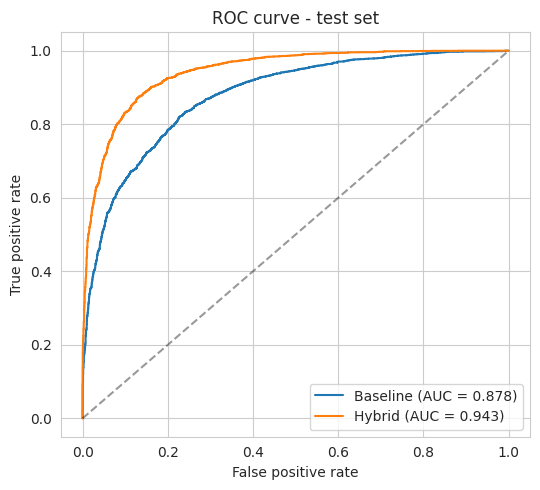

In [68]:
# ============================ CELL 67 ===============================
# ROC curves
plt.figure(figsize=(5.5, 5))
for name, p in [("Baseline", p_base), ("Hybrid", p_hybrid)]:
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.4)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curve - test set"); plt.legend()
plt.tight_layout(); plt.savefig("results/figures/roc_curves.png", dpi=120); plt.show()


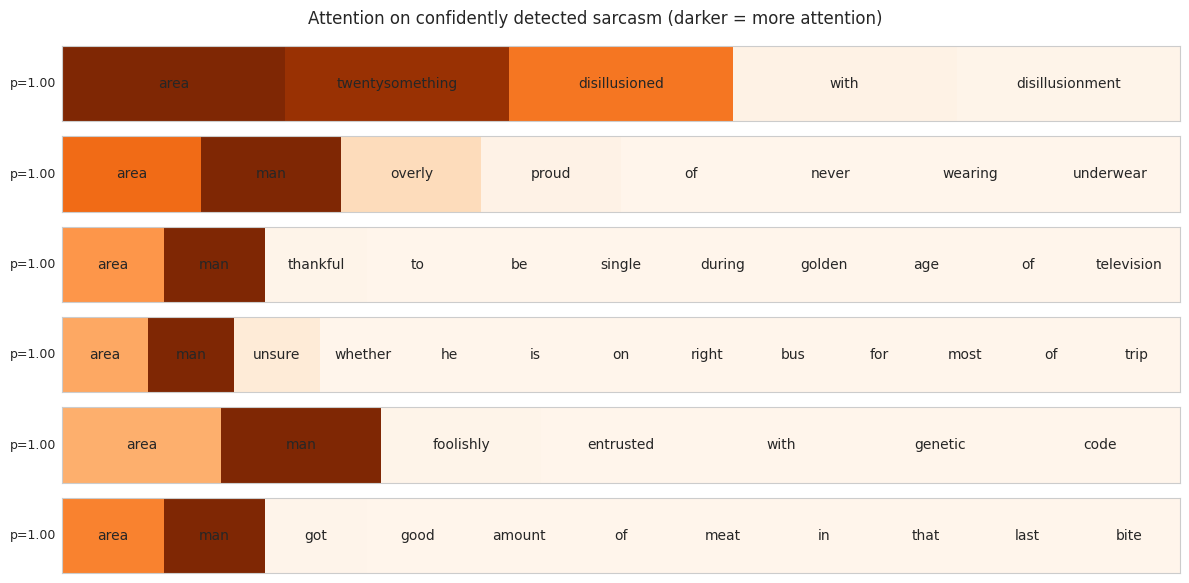

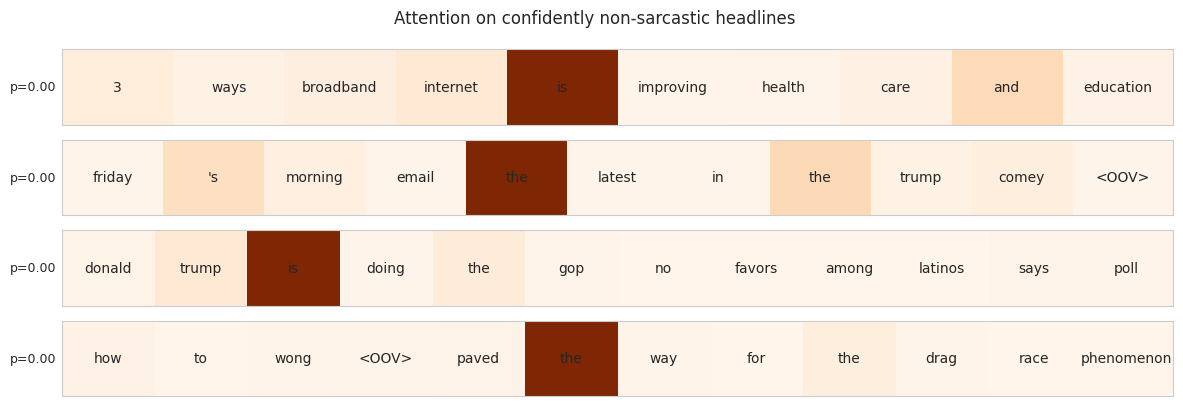

In [69]:
# ============================ CELL 68 ===============================
# Attention heatmaps: which words made the model say "sarcastic"?
alphas = att_model.predict([X_seq_test, X_feat_test], verbose=0)

def plot_attention(rows, title, fname):
    fig, axes = plt.subplots(len(rows), 1, figsize=(12, 0.9 * len(rows) + 0.5))
    axes = np.atleast_1d(axes)
    for ax, i in zip(axes, rows):
        ids = [t for t in X_seq_test[i] if t != 0]
        words = [index_word.get(t, "<OOV>") for t in ids]
        w = alphas[i][:len(ids)][None, :]
        ax.imshow(w, cmap="Oranges", aspect="auto", vmin=0, vmax=w.max())
        for j, word in enumerate(words):
            ax.text(j, 0, word, ha="center", va="center", fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_ylabel(f"p={p_hybrid[i]:.2f}", rotation=0, ha="right", va="center", fontsize=9)
    fig.suptitle(title); plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()

correct_sarc = np.where((y_test == 1) & (pred_hybrid == 1))[0]
top_sarc = correct_sarc[np.argsort(-p_hybrid[correct_sarc])][:6]
plot_attention(top_sarc, "Attention on confidently detected sarcasm (darker = more attention)",
               "results/figures/attention_sarcastic.png")

correct_real = np.where((y_test == 0) & (pred_hybrid == 0))[0]
plot_attention(correct_real[np.argsort(p_hybrid[correct_real])][:4],
               "Attention on confidently non-sarcastic headlines", "results/figures/attention_not_sarcastic.png")


In [70]:
# ============================ CELL 69 ===============================
# Error analysis: where hybrid and baseline disagree
analysis = pd.DataFrame({"headline": test_headlines, "actual": y_test,
                         "p_hybrid": p_hybrid.round(3), "p_base": p_base.round(3)})
hyb_right = analysis[(pred_hybrid == y_test) & (pred_base != y_test)]
base_right = analysis[(pred_hybrid != y_test) & (pred_base == y_test)]
both_wrong = analysis[(pred_hybrid != y_test) & (pred_base != y_test)]

print(f"Hybrid right, baseline wrong: {len(hyb_right)}")
print(f"Baseline right, hybrid wrong: {len(base_right)}")
print(f"Both wrong:                   {len(both_wrong)}\n")
pd.set_option("display.max_colwidth", 100)
print("== Hybrid fixed these (baseline got them wrong) ==")
display(hyb_right.sample(min(8, len(hyb_right)), random_state=SEED))
print("== Both models failed - the genuinely hard cases ==")
display(both_wrong.sample(min(8, len(both_wrong)), random_state=SEED))



Hybrid right, baseline wrong: 807
Baseline right, hybrid wrong: 363
Both wrong:                   391

== Hybrid fixed these (baseline got them wrong) ==


,headline,actual,p_hybrid,p_base
4875,remains of minnesota boy missing since 1989 found,0,0.152,0.638
1946,country music protested in restaurant's kitchen,1,0.931,0.366
1532,paralympian made tv host who wears prosthetic leg 'proud to be disabled',0,0.236,0.908
2285,tesla debuts carless driver,1,0.749,0.333
3842,"in major gaffe, obama forgets to dumb it down",1,0.954,0.250
5610,the biggest fails of the month,0,0.013,0.622
1348,"john bolton, top contender for secretary of state, calls for regime change in iran",0,0.429,0.876
1678,the inside story of how congress sent the stock market tumbling,0,0.025,0.524


== Both models failed - the genuinely hard cases ==


,headline,actual,p_hybrid,p_base
139,trump retweets video from anti-muslim hate group,1,0.010,0.003
489,unambitious terrorists overturn trash can,1,0.491,0.492
403,navy admiral thinks he's 'mr. important',1,0.487,0.147
4433,trump claims substantial portions of the u.s.-mexico laser forcefield have already been built,1,0.079,0.431
5367,christie 2016 comes from nowhere to win republican nomination,1,0.282,0.158
5400,beware intelligent men bearing caustic wits,0,0.592,0.907
790,142 plane crash victims were statistically more likely to have died in a car crash,1,0.075,0.077
4603,masterpiece cakeshop case declared mistrial after clarence thomas tampers with evidence,1,0.161,0.438


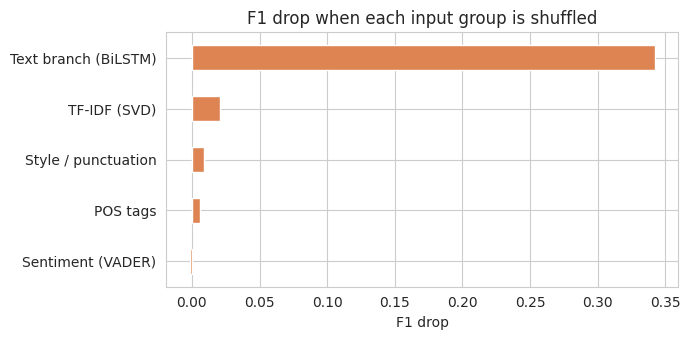

Sentiment (VADER)      -0.0017
POS tags                0.0057
Style / punctuation     0.0086
TF-IDF (SVD)            0.0210
Text branch (BiLSTM)    0.3423
dtype: float64


In [71]:
# ============================ CELL 70 ===============================
# Which NLP feature groups did the hybrid rely on? (permutation importance)
# Shuffle one group's columns across test rows -> breaks its link to the label.
# Bigger F1 drop = the model leaned on that group more. No retraining needed.
def group_of(name):
    if name.startswith(("vader_", "sent_")) or name in ("n_pos_words", "n_neg_words"):
        return "Sentiment (VADER)"
    if name.startswith("pos_") or name == "n_intensifiers":
        return "POS tags"
    if name.startswith("svd_"):
        return "TF-IDF (SVD)"
    return "Style / punctuation"

groups = {}
for j, n in enumerate(FEATURE_NAMES):
    groups.setdefault(group_of(n), []).append(j)

tf.get_logger().setLevel("ERROR")   # hide harmless retracing warnings
base_f1 = f1_score(y_test, pred_hybrid)
rng = np.random.default_rng(SEED)
drops = {}
for g, cols in groups.items():
    scores = []
    for _ in range(3):
        Xf = X_feat_test.copy()
        Xf[:, cols] = Xf[rng.permutation(len(Xf))][:, cols]
        scores.append(f1_score(y_test, (model.predict([X_seq_test, Xf], verbose=0).ravel() >= 0.5).astype(int)))
    drops[g] = base_f1 - np.mean(scores)

# Same test for the whole text branch (shuffle sequences)
Xs = X_seq_test[rng.permutation(len(X_seq_test))]
drops["Text branch (BiLSTM)"] = base_f1 - f1_score(
    y_test, (model.predict([Xs, X_feat_test], verbose=0).ravel() >= 0.5).astype(int))

imp = pd.Series(drops).sort_values()
plt.figure(figsize=(7, 3.5))
imp.plot(kind="barh", color="#DD8452")
plt.title("F1 drop when each input group is shuffled"); plt.xlabel("F1 drop")
plt.tight_layout(); plt.savefig("results/figures/feature_importance.png", dpi=120); plt.show()
print(imp.round(4))


In [72]:
# ============================ CELL 71 ===============================
# Is the improvement statistically significant? McNemar's test
# Compares the two models on the SAME test headlines (counts disagreements).
from scipy.stats import chi2

b = int(((pred_hybrid == y_test) & (pred_base != y_test)).sum())
c = int(((pred_hybrid != y_test) & (pred_base == y_test)).sum())
stat = (abs(b - c) - 1) ** 2 / (b + c) if (b + c) > 0 else 0.0   # with continuity correction
pvalue = chi2.sf(stat, df=1)
print(f"Hybrid-only correct: {b} | Baseline-only correct: {c}")
print(f"McNemar chi2 = {stat:.2f}, p-value = {pvalue:.2e}")
better = "Hybrid" if b > c else "Baseline"
print(f"{better} is significantly better (p < 0.05)" if pvalue < 0.05
      else "Difference is not statistically significant at the 5% level")


Hybrid-only correct: 807 | Baseline-only correct: 363
McNemar chi2 = 167.73, p-value = 2.31e-38
Hybrid is significantly better (p < 0.05)


In [73]:
# ============================ CELL 72 ===============================
# Save final results
with open("results/results_final.json", "w") as f:
    json.dump({k: {m: float(v) for m, v in d.items()} for k, d in all_results.items()}, f, indent=2)
results_df.round(4).to_csv("results/results_final.csv")
analysis.to_csv("results/test_predictions.csv", index=False)
print("Saved results/results_final.json/.csv, results/test_predictions.csv and all figures (*.png)")

# If you mounted Drive:
!cp results/results_final.* results/test_predictions.csv results/figures/*.png /content/drive/MyDrive/sarcasm_project/


Saved results_final.json/.csv, test_predictions.csv and all figures (*.png)


In [74]:
# =====================================================================
# SARCASM DETECTION - PHASE 10: Streamlit Demo
# Add these cells BELOW cell 72 in the same Colab notebook.
#
# Needs two extra files: app/app.py and app/sarcasm_inference.py
# (upload them in cell 74). The demo runs in Colab and gets a public
# link through a free Cloudflare tunnel - no account needed.
# =====================================================================


# ============================ CELL 73 ===============================
# Check that every file the app needs exists
import os
needed = ["models/hybrid_final.keras", "models/nlp_feature_pipeline.joblib", "models/dl_vocab.pkl", "models/training_info.json"]
optional = ["results/results_final.csv", "results/figures/model_comparison.png", "results/figures/confusion_matrices.png", "results/figures/roc_curves.png",
            "results/figures/attention_sarcastic.png", "results/figures/feature_importance.png", "results/figures/learning_curves.png"]
for f in needed + optional:
    status = "OK" if os.path.exists(f) else ("MISSING (required!)" if f in needed else "missing (optional)")
    print(f"{f:<30} {status}")
# If files are missing after a restart, copy them back from Drive:
# !cp /content/drive/MyDrive/sarcasm_project/* .


hybrid_final.keras             OK
nlp_feature_pipeline.joblib    OK
dl_vocab.pkl                   OK
training_info.json             OK
results_final.csv              OK
model_comparison.png           OK
confusion_matrices.png         OK
roc_curves.png                 OK
attention_sarcastic.png        OK
feature_importance.png         OK
learning_curves.png            OK


In [75]:
# ============================ CELL 74 ===============================
# Upload app/app.py and app/sarcasm_inference.py (or drag them into the Files panel on the left)
from google.colab import files
if not (os.path.exists("app/app.py") and os.path.exists("app/sarcasm_inference.py")):
    files.upload()
print("app/app.py:", os.path.exists("app/app.py"), "| app/sarcasm_inference.py:", os.path.exists("app/sarcasm_inference.py"))


Saving sarcasm_inference.py to sarcasm_inference.py
Saving app.py to app.py
app.py: True | sarcasm_inference.py: True


In [76]:
# ============================ CELL 75 ===============================
# CRITICAL CHECK: the app's pipeline must give the SAME predictions as the notebook.
# If preprocessing differs even slightly, the demo silently gives wrong answers.
import numpy as np, pandas as pd, keras
import sys
sys.path.insert(0, "app")
from sarcasm_inference import SarcasmDetector

det = SarcasmDetector("models")
test_idx = np.load("features/test_idx.npy")
df_check = pd.read_csv("data/sarcasm_preprocessed.csv")
model_nb = keras.models.load_model("models/hybrid_final.keras")
p_nb = model_nb.predict([np.load("features/X_seq_test.npy"), np.load("features/X_feat_test.npy")], verbose=0).ravel()

n = 300
p_app = np.array([det.predict(h)["probability"] for h in df_check.loc[test_idx[:n], "headline"]])
diff = np.abs(p_app - p_nb[:n]).max()
print(f"Max probability difference over {n} test headlines: {diff:.2e}")
print("PASS - app matches notebook" if diff < 1e-4 else "FAIL - preprocessing mismatch, check constants")


Max probability difference over 300 test headlines: 2.98e-07
PASS - app matches notebook


In [77]:
# ============================ CELL 76 ===============================
# Try your own headlines in the notebook
for h in ["area man thrilled to spend entire weekend doing taxes",
          "local woman just loves being stuck in traffic for 3 hours",
          "senate passes bipartisan infrastructure bill",
          "scientists discover new species of frog in amazon",
          "nation's cats unveil bold new plan to knock everything off tables"]:
    r = det.predict(h)
    top_word = r["tokens"][int(np.argmax(r["attention"]))]
    print(f"{r['probability']:.2f}  {'SARCASTIC' if r['is_sarcastic'] else 'normal   '}  "
          f"(focus: '{top_word}')  {h}")


1.00  SARCASTIC  (focus: 'man')  area man thrilled to spend entire weekend doing taxes
1.00  SARCASTIC  (focus: 'woman')  local woman just loves being stuck in traffic for 3 hours
0.10  normal     (focus: 'senate')  senate passes bipartisan infrastructure bill
1.00  SARCASTIC  (focus: 'scientists')  scientists discover new species of frog in amazon
1.00  SARCASTIC  (focus: 'nation')  nation's cats unveil bold new plan to knock everything off tables


In [78]:
# ============================ CELL 77 ===============================
# Launch Streamlit + public link (link works while this Colab session is alive)
!pip install -q streamlit
!wget -q -nc -O cloudflared https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 && chmod +x cloudflared

import subprocess, time, re
subprocess.Popen(["streamlit", "run", "app/app.py", "--server.port", "8501", "--server.headless", "true"],
                 stdout=open("streamlit.log", "w"), stderr=subprocess.STDOUT)
time.sleep(8)
tunnel = subprocess.Popen(["./cloudflared", "tunnel", "--url", "http://localhost:8501"],
                          stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
for line in tunnel.stdout:
    m = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", line)
    if m:
        print("\n🚀 Your app is live at:", m.group(0))
        print("(first load takes ~20 s while the model loads)")
        break
# If the page shows an error, check the log:  !tail -30 streamlit.log


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 77.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 68.9 MB/s eta 0:00:00

🚀 Your app is live at: https://amenities-dennis-packet-endorsement.trycloudflare.com
(first load takes ~20 s while the model loads)


In [ ]:
# ============================ CELL 78 ===============================
# Download everything as one zip (to run locally or submit)
import zipfile
to_zip = ["app/app.py", "app/sarcasm_inference.py"] + [f for f in needed + optional if os.path.exists(f)]
with zipfile.ZipFile("sarcasm_detector_app.zip", "w") as z:
    for f in to_zip:
        z.write(f)
files.download("sarcasm_detector_app.zip")
# Run locally:  pip install -r requirements.txt  ->  streamlit run app/app.py
